=== HASIL EVALUASI MODEL LOGISTIC REGRESSION ===
Akurasi Model : 80.70%

Classification Report:
              precision    recall  f1-score   support

   Tetap (0)       0.85      0.89      0.87      1035
   Churn (1)       0.66      0.57      0.61       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



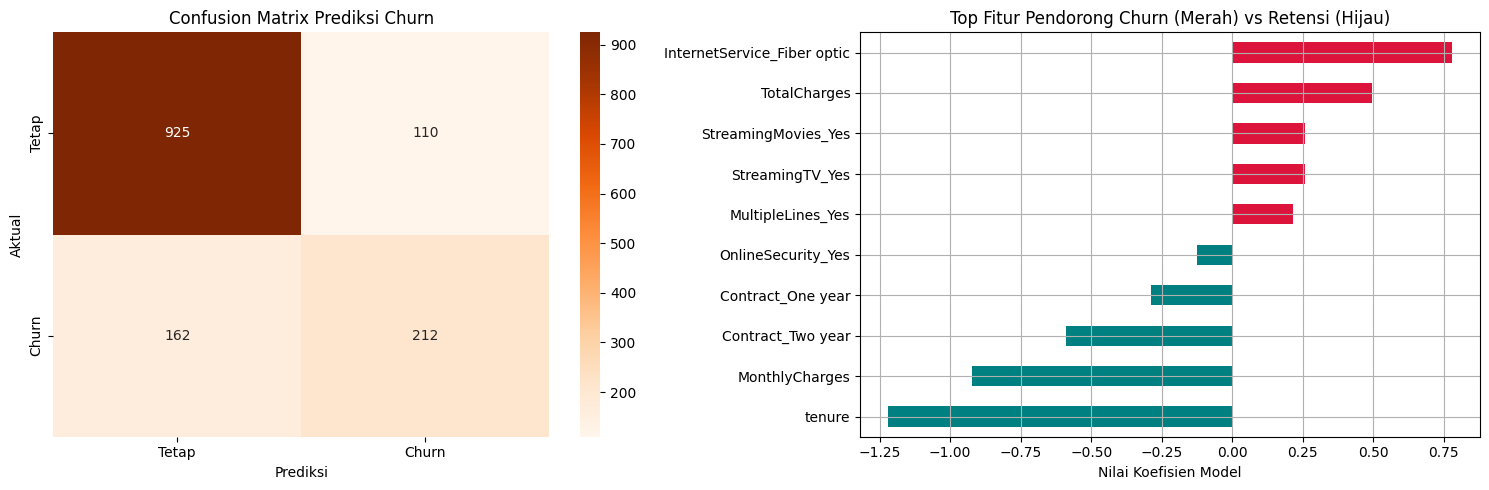

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. LOAD DATASET
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

# 2. PEMBERSIHAN DATA & PREPROCESSING

# A. Hapus kolom non-prediktif
df = df.drop(columns=['customerID'])

# B. Konversi TotalCharges ke numerik & tangani missing values
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].str.strip(), errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

# C. Mapping target Churn menjadi binary (1 / 0)
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# D. Encoding variabel kategorik (0/1)
df_encoded = pd.get_dummies(df, drop_first=True, dtype=int)

# E. Pemisahan Fitur (X) dan Target (y)
X = df_encoded.drop(columns=['Churn'])
y = df_encoded['Churn']

# F. Train-Test Split (80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# G. Scaling Fitur
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. TRAINING MODEL
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

# 4. PREDIKSI & EVALUASI
y_pred = model.predict(X_test_scaled)
acc = accuracy_score(y_test, y_pred)

print("=== HASIL EVALUASI MODEL LOGISTIC REGRESSION ===")
print(f"Akurasi Model : {acc * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Tetap (0)', 'Churn (1)']))

# 5. VISUALISASI HASIL
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Visualisasi 1: Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Oranges',
    ax=axes[0],
    xticklabels=['Tetap', 'Churn'],
    yticklabels=['Tetap', 'Churn']
)
axes[0].set_xlabel("Prediksi")
axes[0].set_ylabel("Aktual")
axes[0].set_title("Confusion Matrix Prediksi Churn")

# Visualisasi 2: Top Fitur Paling Berpengaruh
coef = pd.Series(model.coef_[0], index=X.columns)
top_coef = pd.concat([coef.nlargest(5), coef.nsmallest(5)]).sort_values()
top_coef.plot(
    kind='barh',
    ax=axes[1],
    color=['teal' if x < 0 else 'crimson' for x in top_coef]
)
axes[1].set_title("Top Fitur Pendorong Churn (Merah) vs Retensi (Hijau)")
axes[1].set_xlabel("Nilai Koefisien Model")
axes[1].grid(True)

plt.tight_layout()
plt.show()